In [1]:
# ---- BLOCK 1: LOAD DATA ----
import numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_csv('biomass_dataset_v2.csv')
print(df.shape)                                  # expect (5265, 37)
print(df['year'].value_counts().sort_index())    # ~1,050 rows per year
df[['year', 'treatment', 'dap', 'dssat_stage_name', 'dssat_biomass_kg_ha']].head()

(5265, 37)
year
2019    1048
2020    1049
2021    1048
2022    1064
2023    1056
Name: count, dtype: int64


,year,treatment,dap,dssat_stage_name,dssat_biomass_kg_ha
0,2019,1,7,"Vegetative, before first flower",5
1,2019,1,8,"Vegetative, before first flower",6
2,2019,1,9,"Vegetative, before first flower",6
3,2019,1,10,"Vegetative, before first flower",8
4,2019,1,11,"Vegetative, before first flower",9


In [2]:
# ---- BLOCK 2: FEATURES AND TARGET ----
s2_bands = ['S2_B1_CoastalAerosol', 'S2_B2_Blue', 'S2_B3_Green', 'S2_B4_Red',
            'S2_B5_RedEdge1', 'S2_B6_RedEdge2', 'S2_B7_RedEdge3', 'S2_B8_NIR',
            'S2_B8A_NIR_Narrow', 'S2_B9_WaterVapor', 'S2_B11_SWIR1', 'S2_B12_SWIR2']
features = s2_bands + ['dap']                    # 12 Sentinel-2 bands + DAP
target = 'dssat_biomass_kg_ha'                   # simulated biomass (kg/ha)
print(len(features), "input features")
print("Missing values in model columns:", int(df[features + [target]].isna().sum().sum()))

13 input features
Missing values in model columns: 0


In [3]:
# ---- BLOCK 3: TRAIN (2019-2022) / TEST (2023) ----
train = df[df['year'] <= 2022]
test = df[df['year'] == 2023].copy()
print("Train rows:", len(train), "| Test rows:", len(test))   # expect 4209 / 1056

model = LinearRegression().fit(train[features], train[target])

Train rows: 4209 | Test rows: 1056


In [4]:
# ---- BLOCK 4: PREDICT AND CLIP NEGATIVES ----
raw = model.predict(test[features])
print("Negative raw predictions:", int((raw < 0).sum()))
test['pred'] = np.clip(raw, 0, None)             # biomass cannot be negative
test['resid'] = test['pred'] - test[target]      # predicted minus actual

Negative raw predictions: 153


In [5]:
# ---- BLOCK 5: EVALUATE ----
actual, pred, resid = test[target].to_numpy(), test['pred'].to_numpy(), test['resid'].to_numpy()
elig = actual > 500
print(f"RMSE:           {np.sqrt(np.mean(resid**2)):.3f} kg/ha   (expect 694.235)")
print(f"R2:             {r2_score(actual, pred):.3f}              (expect 0.877)")
print(f"Mean residual:  {resid.mean():+.3f} kg/ha   (expect +332.972)")
print(f"Within +/-10% (actual > 500): "
      f"{100*np.mean(np.abs(resid[elig]) <= 0.10*actual[elig]):.2f}%  (expect 28.65%)")

RMSE:           694.235 kg/ha   (expect 694.235)
R2:             0.877              (expect 0.877)
Mean residual:  +332.972 kg/ha   (expect +332.972)
Within +/-10% (actual > 500): 28.65%  (expect 28.65%)


In [6]:
# ---- BLOCK 6: EXAMPLE PREDICTIONS ----
test[['year', 'treatment', 'dap', 'dssat_stage_name', target, 'pred', 'resid']].sample(8, random_state=42).round(1)

,year,treatment,dap,dssat_stage_name,dssat_biomass_kg_ha,pred,resid
1312,2023,2,134,R8 harvest maturity,3415,4047.6,632.6
4515,2023,7,46,R1 first flower,1535,2370.4,835.4
4529,2023,7,60,R5 boll filling,3885,3901.0,16.0
5216,2023,8,89,R7 physiological maturity begins,5202,5394.5,192.5
614,2023,1,94,R7 physiological maturity begins,4627,5234.3,607.3
2561,2023,4,67,R5 boll filling,4881,4058.3,-822.7
1236,2023,2,58,R5 boll filling,1269,1539.5,270.5
5197,2023,8,70,R5 boll filling,5275,4630.8,-644.2


In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

s2_bands = ['S2_B1_CoastalAerosol', 'S2_B2_Blue', 'S2_B3_Green', 'S2_B4_Red',
            'S2_B5_RedEdge1', 'S2_B6_RedEdge2', 'S2_B7_RedEdge3', 'S2_B8_NIR',
            'S2_B8A_NIR_Narrow', 'S2_B9_WaterVapor', 'S2_B11_SWIR1', 'S2_B12_SWIR2']
feats = s2_bands + ['dap']
target = 'dssat_biomass_kg_ha'
held_out_years = [2019, 2020, 2021, 2023]   # 2022 stays in training every fold

d = pd.read_csv('biomass_dataset_v2.csv')
d['trt_num'] = d['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)
d['stage'] = d['dssat_stage_name'].map(lambda s: 'Veg' if s.startswith('Veg') else s.split(' ')[0])

parts = []
for y in held_out_years:
    tr, te = d[d['year'] != y], d[d['year'] == y].copy()
    m = LinearRegression().fit(tr[feats], tr[target])
    te['pred'] = np.clip(m.predict(te[feats]), 0, None)
    te['resid'] = te['pred'] - te[target]
    parts.append(te)
loo = pd.concat(parts, ignore_index=True)

rmse = lambda r: np.sqrt(np.mean(np.asarray(r) ** 2))
print("CHECK pooled RMSE (expect 828.762):", round(rmse(loo['resid']), 3),
      "| rows (expect 4201):", len(loo))

CHECK pooled RMSE (expect 828.762): 828.762 | rows (expect 4201): 4201


FOUR-YEAR METRICS (expect pooled RMSE 828.762, R2 ~0.88, within10 ~27.75):
             n      RMSE     R2  MeanResid  Within10%_>500
2019    1048.0   937.498  0.859   -263.360          24.802
2020    1049.0   591.438  0.924     -7.596          42.930
2021    1048.0  1019.122  0.857   -464.999          14.341
2023    1056.0   694.235  0.877    332.972          28.646
Pooled  4201.0   828.762  0.877    -99.898          27.747


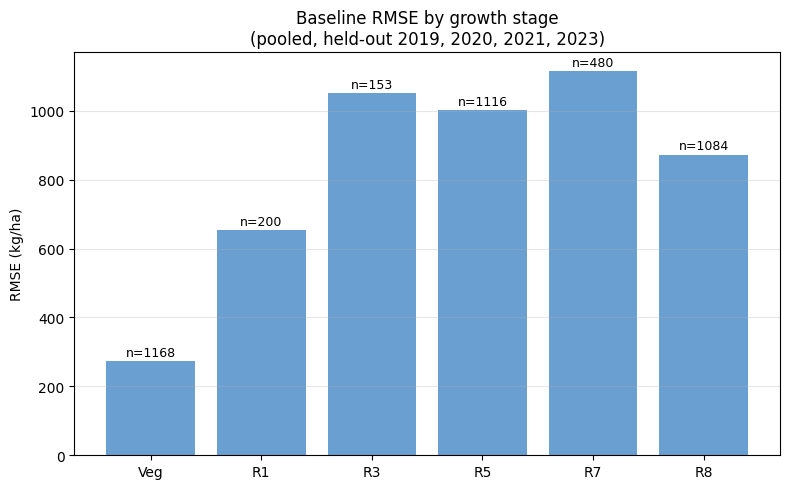

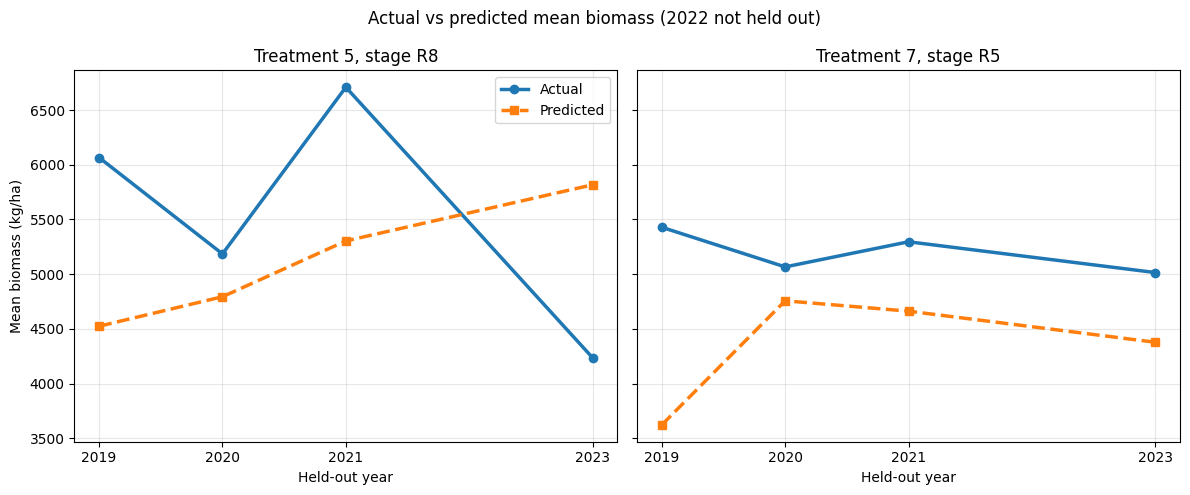

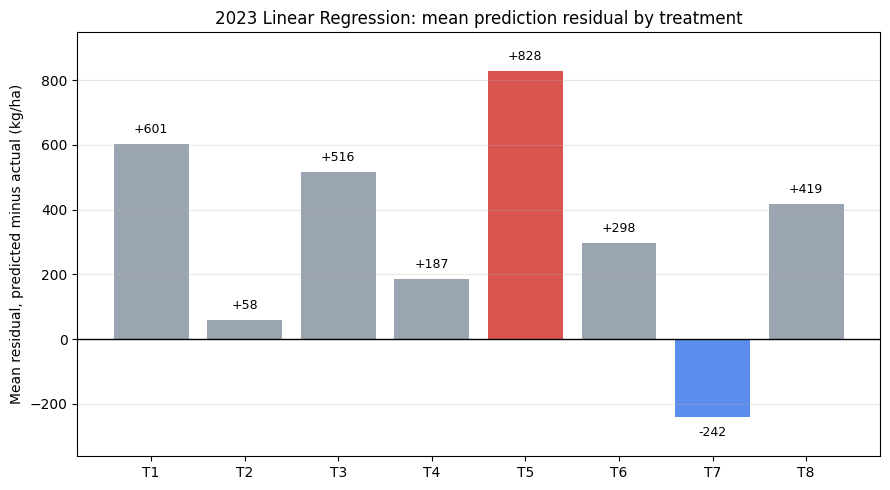

In [8]:
order = ['Veg', 'R1', 'R3', 'R5', 'R7', 'R8']

# ---------- TABLE: four held-out years + pooled ----------
def metrics(x):
    a, p, r = x[target].to_numpy(), x['pred'].to_numpy(), x['resid'].to_numpy()
    e = a > 500
    return pd.Series({'n': len(x), 'RMSE': rmse(r), 'R2': r2_score(a, p),
                      'MeanResid': r.mean(),
                      'Within10%_>500': 100 * np.mean(np.abs(r[e]) <= 0.10 * a[e])})
tab = pd.DataFrame({y: metrics(loo[loo.year == y]) for y in held_out_years}).T
tab.loc['Pooled'] = metrics(loo)
print("FOUR-YEAR METRICS (expect pooled RMSE 828.762, R2 ~0.88, within10 ~27.75):")
print(tab.round(3).to_string())

# ---------- CHART 1: RMSE by stage ----------
st = loo.groupby('stage')['resid'].apply(rmse).reindex(order)
cnt = loo.groupby('stage').size().reindex(order)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(order, st.values, color='#6a9fd1')
for b, n in zip(bars, cnt):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 15, f'n={n}', ha='center', fontsize=9)
ax.set_ylabel('RMSE (kg/ha)')
ax.set_title('Baseline RMSE by growth stage\n(pooled, held-out 2019, 2020, 2021, 2023)')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('Chart_RMSE_by_stage.png', dpi=200); plt.show()

# ---------- CHART 2: T5-R8 and T7-R5 actual vs predicted by year ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (t, s) in zip(axes, [(5, 'R8'), (7, 'R5')]):
    x = loo[(loo.trt_num == t) & (loo.stage == s)].groupby('year')[[target, 'pred']].mean()
    ax.plot(x.index, x[target], marker='o', lw=2.5, label='Actual')
    ax.plot(x.index, x['pred'], marker='s', lw=2.5, ls='--', label='Predicted')
    ax.set_xticks(x.index)
    ax.set_title(f'Treatment {t}, stage {s}')
    ax.set_xlabel('Held-out year'); ax.grid(alpha=0.3)
axes[0].set_ylabel('Mean biomass (kg/ha)'); axes[0].legend()
plt.suptitle('Actual vs predicted mean biomass (2022 not held out)')
plt.tight_layout(); plt.savefig('Chart_T5R8_T7R5_by_year.png', dpi=200); plt.show()

# ---------- CHART 3: 2023 mean residual by treatment ----------
r23 = loo[loo.year == 2023].groupby('trt_num')['resid'].mean()
colors = ['#d9534f' if t == 5 else '#5b8def' if t == 7 else '#9aa5b1' for t in r23.index]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([f'T{t}' for t in r23.index], r23.values, color=colors)
ax.axhline(0, color='black', lw=1)
for b, v in zip(bars, r23.values):
    ax.text(b.get_x() + b.get_width()/2, v + (25 if v >= 0 else -25),
            f'{v:+.0f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
ax.set_ylim(r23.min() - 120, r23.max() + 120)
ax.set_ylabel('Mean residual, predicted minus actual (kg/ha)')
ax.set_title('2023 Linear Regression: mean prediction residual by treatment')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('Chart_Treatment_Bias_2023.png', dpi=200); plt.show()

In [9]:
X = d.loc[d['year'] <= 2022, feats]          # the official training set
Z = (X - X.mean()) / X.std()

print("Condition number (standardized):", round(np.linalg.cond(Z.values), 1))

vif = {}
for f in feats:
    others = [c for c in feats if c != f]
    r2 = LinearRegression().fit(Z[others], Z[f]).score(Z[others], Z[f])
    vif[f] = np.inf if r2 >= 0.999999 else 1 / (1 - r2)
v = pd.Series(vif).sort_values(ascending=False)
print("\nVIF (higher = more redundant; >10 is a common warning level):")
print(v.round(1).to_string())

print("\nCorrelation NIR vs NIR_narrow:", round(X['S2_B8_NIR'].corr(X['S2_B8A_NIR_Narrow']), 4))
print("Correlation NIR vs RedEdge3:", round(X['S2_B8_NIR'].corr(X['S2_B7_RedEdge3']), 4))

Condition number (standardized): 227322.2

VIF (higher = more redundant; >10 is a common warning level):
S2_B7_RedEdge3               inf
S2_B9_WaterVapor             inf
S2_B8A_NIR_Narrow            inf
S2_B8_NIR                    inf
S2_B4_Red               163817.9
S2_B1_CoastalAerosol    115714.3
S2_B11_SWIR1             41123.8
S2_B3_Green              31286.4
S2_B12_SWIR2             27908.6
S2_B5_RedEdge1           20766.7
S2_B6_RedEdge2           20695.7
S2_B2_Blue                1885.9
dap                          4.5

Correlation NIR vs NIR_narrow: 0.9996
Correlation NIR vs RedEdge3: 0.997


RMSE: 694.235 | mean residual: 332.972


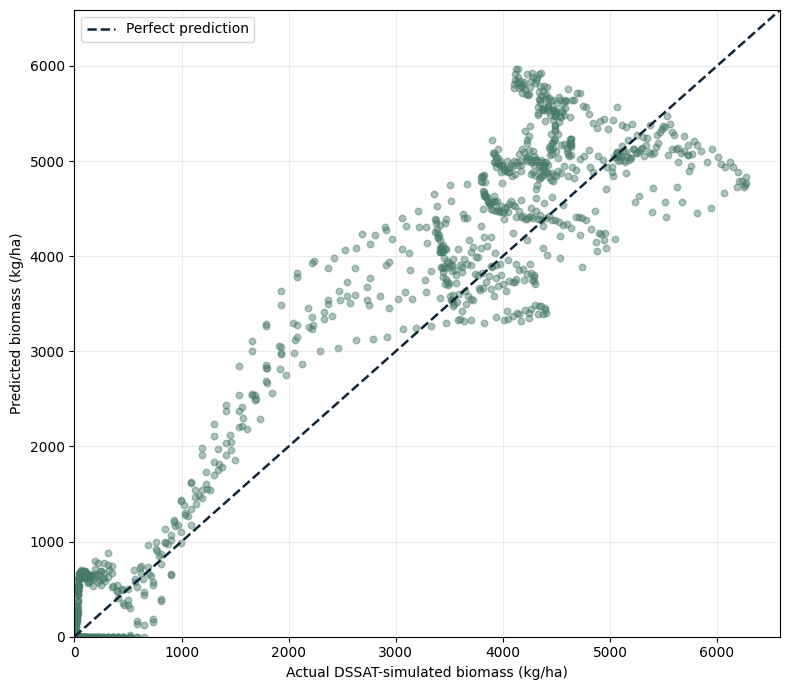

In [10]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

df = pd.read_csv("biomass_dataset_v2.csv")
features = [c for c in df.columns if c.startswith("S2_")] + ["dap"]
target = "dssat_biomass_kg_ha"

train = df[df["year"] <= 2022]
test = df[df["year"] == 2023]

model = LinearRegression().fit(train[features], train[target])
pred = np.maximum(model.predict(test[features]), 0)
actual = test[target].values

rmse = np.sqrt(mean_squared_error(actual, pred))
print("RMSE:", round(rmse, 3), "| mean residual:", round((pred - actual).mean(), 3))

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(actual, pred, color="#477A68", alpha=0.45, s=22)
lim = max(actual.max(), pred.max()) * 1.05
ax.plot([0, lim], [0, lim], "--", color="#102438", linewidth=1.8, label="Perfect prediction")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Actual DSSAT-simulated biomass (kg/ha)")
ax.set_ylabel("Predicted biomass (kg/ha)")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("Slide15_Actual_vs_Predicted_2023.png", dpi=200)
plt.show()

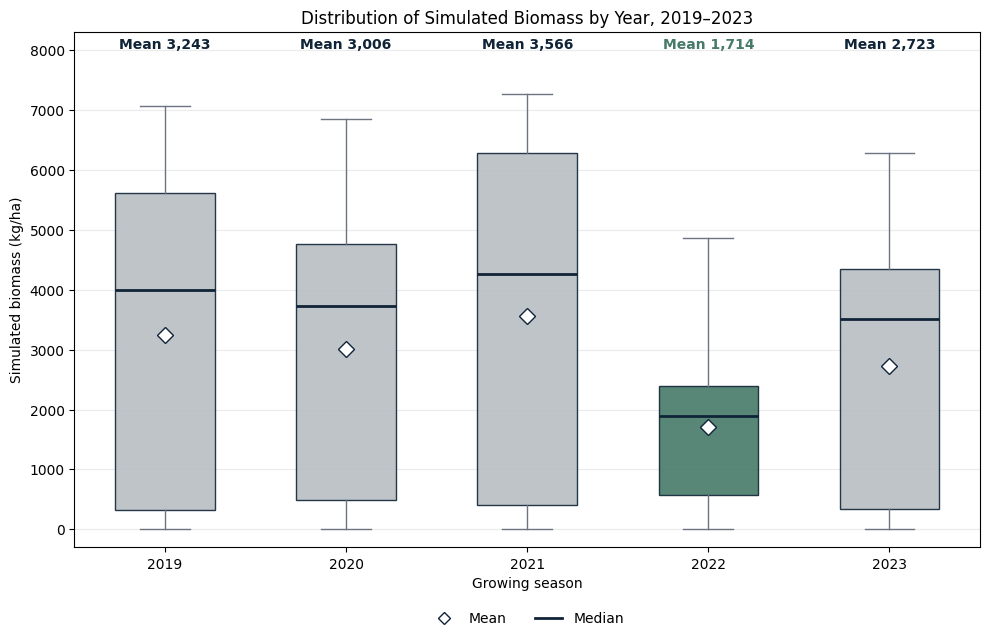

         mean  median  count
year                        
2019  3242.79  3987.0   1048
2020  3006.39  3732.0   1049
2021  3565.98  4264.0   1048
2022  1713.51  1890.5   1064
2023  2722.58  3515.5   1056


In [12]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/biomass_dataset_v2.csv')
target = 'dssat_biomass_kg_ha'
years = [2019, 2020, 2021, 2022, 2023]

data = [df.loc[df['year'] == y, target].values for y in years]

fig, ax = plt.subplots(figsize=(10, 6.5))
bp = ax.boxplot(
    data, positions=range(len(years)), widths=0.55, patch_artist=True,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor='white',
                   markeredgecolor='#102438', markersize=8),
    medianprops=dict(color='#102438', linewidth=2),
    whiskerprops=dict(color='#6B7480'),
    capprops=dict(color='#6B7480'),
    flierprops=dict(marker='o', markersize=3, alpha=0.3,
                    markerfacecolor='#6B7480', markeredgecolor='none')
)

ax.set_ylim(-300, 8300)

# Highlight 2022
for box, y in zip(bp['boxes'], years):
    box.set_facecolor('#477A68' if y == 2022 else '#B8BEC4')
    box.set_edgecolor('#102438')
    box.set_alpha(0.9)

# Label the mean above each box
for i, y in enumerate(years):
    m = df.loc[df['year'] == y, target].mean()
    ax.text(i, 8200, f"Mean {m:,.0f}",
            ha='center', va='top', fontsize=10,
            color='#477A68' if y == 2022 else '#102438', fontweight='bold')

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)
ax.set_xlabel('Growing season')
ax.set_ylabel('Simulated biomass (kg/ha)')
ax.set_title('Distribution of Simulated Biomass by Year, 2019–2023')
ax.grid(axis='y', alpha=0.25)

# Legend below the chart
ax.plot([], [], 'D', markerfacecolor='white', markeredgecolor='#102438', label='Mean')
ax.plot([], [], '-', color='#102438', linewidth=2, label='Median')
ax.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, -0.1), frameon=False)

plt.tight_layout()
plt.savefig('Biomass_distribution_by_year.png', dpi=200, bbox_inches='tight')
plt.show()

print(df.groupby('year')[target].agg(['mean', 'median', 'count']).round(2))

Stage order: ['Vegetative, before first flower', 'R1 first flower', 'R3 first boll', 'R5 boll filling', 'R7 physiological maturity begins', 'R8 harvest maturity']
dssat_stage_name  Vegetative, before first flower  R1 first flower  R3 first boll  R5 boll filling  R7 physiological maturity begins  R8 harvest maturity
trt_num                                                                                                                                                  
1                                            76.0            516.0          882.0           3290.0                            5817.0               5674.0
2                                            76.0            519.0          887.0           3117.0                            4432.0               3992.0
3                                           231.0           1394.0         2098.0           4740.0                            5473.0               5033.0
4                                           231.0           1394.0 

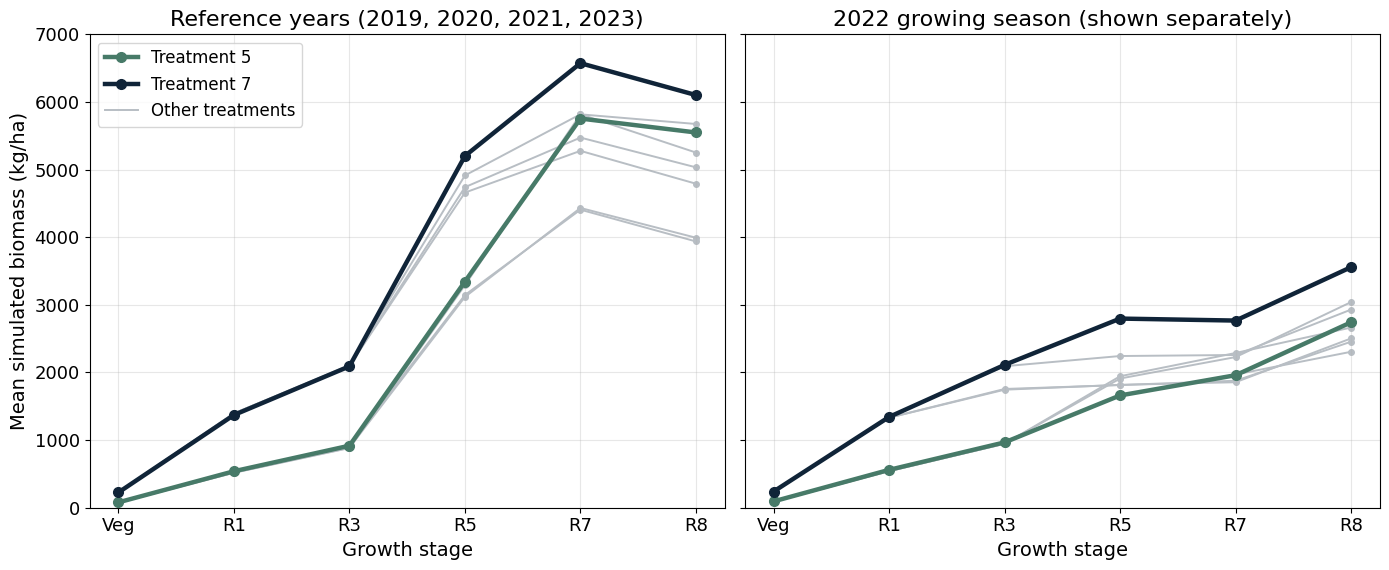

In [13]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

df = pd.read_csv('biomass_dataset_v2.csv')
target = 'dssat_biomass_kg_ha'
reference_years = [2019, 2020, 2021, 2023]

df['trt_num'] = df['treatment'].astype(str).str.extract(r'(\d+)$')[0].astype(int)
stage_col = 'dssat_stage_name'
stage_order = df.groupby(stage_col)['dap'].median().sort_values().index.tolist()
print('Stage order:', stage_order)

yr = df.groupby(['year', 'trt_num', stage_col])[target].mean().reset_index()

ref_mean = (yr[yr['year'].isin(reference_years)]
            .groupby(['trt_num', stage_col])[target].mean()
            .unstack().reindex(columns=stage_order))
m22 = (yr[yr['year'] == 2022]
       .pivot(index='trt_num', columns=stage_col, values=target)
       .reindex(columns=stage_order))

print(ref_mean.round(0).to_string())
print(m22.round(0).to_string())

short = {s: ('Veg' if s.startswith('Veg') else s.split(' ')[0]) for s in stage_order}
labels = [short[s] for s in stage_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
panels = [(axes[0], ref_mean, 'Reference years (2019, 2020, 2021, 2023)'),
          (axes[1], m22, '2022 growing season (shown separately)')]

for ax, tbl, title in panels:
    for t in tbl.index:
        if t in (5, 7):
            continue
        ax.plot(labels, tbl.loc[t].values, color='#B8BEC4', lw=1.4, marker='o', ms=4, zorder=1)
    ax.plot(labels, tbl.loc[5].values, color='#477A68', lw=3.2, marker='o', ms=7, label='Treatment 5', zorder=3)
    ax.plot(labels, tbl.loc[7].values, color='#102438', lw=3.2, marker='o', ms=7, label='Treatment 7', zorder=3)
    ax.plot([], [], color='#B8BEC4', lw=1.4, label='Other treatments')
    ax.set_title(title, fontsize=16)
    ax.set_xlabel('Growth stage', fontsize=14)
    ax.tick_params(labelsize=13)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 7000)

axes[0].set_ylabel('Mean simulated biomass (kg/ha)', fontsize=14)
axes[0].legend(fontsize=12, loc='upper left')
plt.tight_layout()
plt.savefig('Task1_biomass_by_stage_clean.png', dpi=200, bbox_inches='tight')
plt.show()